# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Emma Chung, Kevin Sun, Anastacia Oliynyk

**Date:** 11/11/2026

Q1

Original shape: (16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


,Missing values
sale_date,0
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
hvac_description,7
exterior,1


Exact duplicates removed: 46
Additional records excluded: 83
Cleaned shape: (16685, 19)


,count,mean,min,25%,50%,75%,max,std
sale_date,16685,2020-07-16 17:16:05.537908224,2020-01-01 00:00:00,2020-04-27 00:00:00,2020-07-27 00:00:00,2020-10-09 00:00:00,2020-12-31 00:00:00,NaN
sale_price,16685.0,460711.533833,2000.0,348000.0,416500.0,523000.0,6130000.0,231969.664344
house_square_feet,16685.0,1882.402158,200.0,1320.0,1774.0,2352.0,9510.0,757.693748
attic_finished_square_feet,16685.0,25.010668,0.0,0.0,0.0,0.0,1212.0,102.146437
basement_square_feet,16685.0,168.610488,0.0,0.0,0.0,0.0,4000.0,430.021766
attached_garage_square_feet,16685.0,364.864249,0.0,0.0,422.0,528.0,2816.0,286.494195
detached_garage_square_feet,16685.0,38.532514,0.0,0.0,0.0,0.0,3664.0,165.237108
fireplaces,16685.0,0.891399,0.0,1.0,1.0,1.0,5.0,0.595436
stories,16685.0,1.561822,1.0,1.0,2.0,2.0,3.0,0.507524
year_built,16685.0,1980.405394,1880.0,1959.0,1990.0,2006.0,2021.0,33.310856


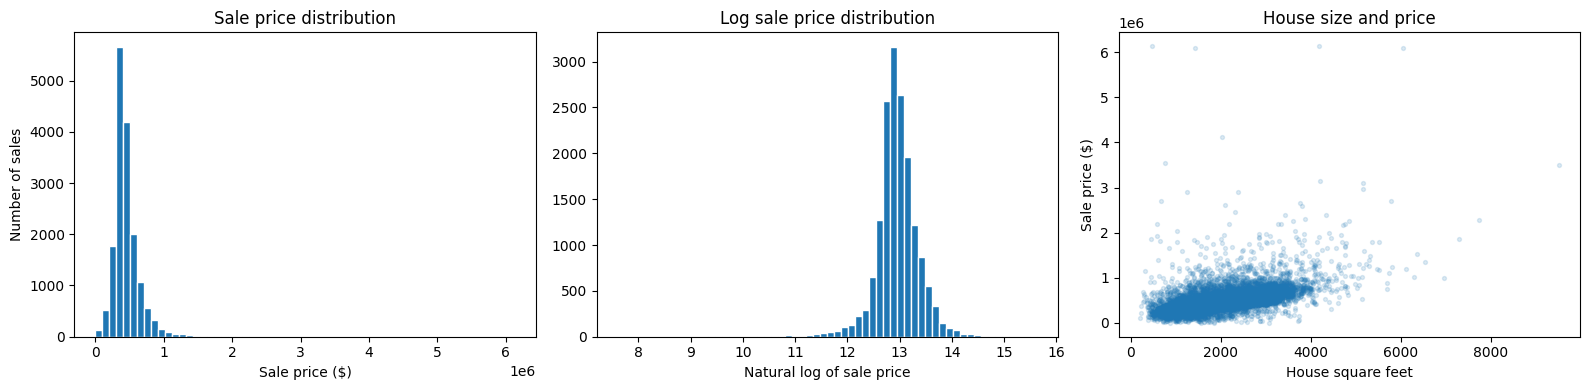

,Correlation with price
attic_finished_square_feet,0.022428
detached_garage_square_feet,0.053637
stories,0.175749
bedrooms,0.219480
year_built,0.232631
basement_square_feet,0.276343
attached_garage_square_feet,0.318509
fireplaces,0.357741
bathrooms,0.423721
house_square_feet,0.539416


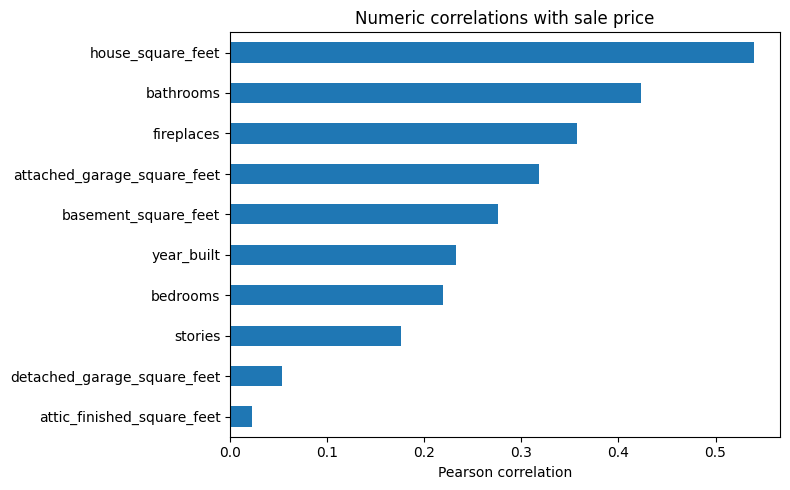

In [72]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score

raw = pd.read_csv("/data/pierce_county_house_sales.csv")

print("Original shape:", raw.shape)
display(raw.head())
display(raw.isna().sum().rename("Missing values"))

df = raw.drop_duplicates().copy()
print("Exact duplicates removed:", len(raw) - len(df))

valid = (
    (df["sale_price"] > 0)
    & (df["house_square_feet"] > 0)
    & (df["bedrooms"] > 0)
    & (df["bathrooms"] > 0)
    & (df["stories"] > 0)
)

print("Additional records excluded:", (~valid).sum())
df = df.loc[valid].copy()

df["sale_date"] = pd.to_datetime(df["sale_date"])

for column in ["waterfront_type", "view_quality"]:
    df[column] = df[column].fillna("None recorded")

print("Cleaned shape:", df.shape)
display(df.describe().T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df["sale_price"], bins=60, edgecolor="white")
axes[0].set(
    title="Sale price distribution",
    xlabel="Sale price ($)",
    ylabel="Number of sales",
)

axes[1].hist(np.log(df["sale_price"]), bins=60, edgecolor="white")
axes[1].set(
    title="Log sale price distribution",
    xlabel="Natural log of sale price",
)

axes[2].scatter(
    df["house_square_feet"], df["sale_price"],
    alpha=0.15, s=8
)
axes[2].set(
    title="House size and price",
    xlabel="House square feet",
    ylabel="Sale price ($)",
)

plt.tight_layout()
plt.show()

correlations = (
    df.select_dtypes("number")
    .corr()["sale_price"]
    .drop("sale_price")
    .sort_values()
)

display(correlations.rename("Correlation with price"))

correlations.plot.barh(figsize=(8, 5))
plt.title("Numeric correlations with sale price")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

The original dataset contains 16,814 observations and 19 columns. I removed 46 exact duplicates and excluded 83 additional observations with zero bedrooms, bathrooms, or stories, treating these as unusable records for this analysis. The cleaned dataset contains 16,685 observations. Missing waterfront and view values were labeled "None recorded." Other missing categorical values were imputed using the most frequent training-set category.

Sale prices are right-skewed, with a mean of approximately 416,500 dollars and a maximum of 6,130,000 dollars. These extremes warrant investigation, but I retained them because they are not necessarily errors. House size has the strongest individual numeric correlation with price, approximately 0.539.


Q2 and Q3

In [73]:
# 2. Prepare variables
# 3. Create the 80/20 train-test split

df["sale_day"] = (
    df["sale_date"] - pd.Timestamp("2020-01-01")
).dt.days

X = df.drop(columns=["sale_price", "sale_date"])
y = df["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


def make_preprocessor(features):
    numeric_columns = features.select_dtypes("number").columns.tolist()
    categorical_columns = features.select_dtypes("object").columns.tolist()

    numeric_pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
    )

    categorical_pipeline = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False,
        ),
    )

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])


# All learned preprocessing is fitted inside each training fold.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

Training observations: 13348
Test observations: 3337


I randomly divided the cleaned data into 80% training and 20% testing using random_state=42. This produced 13,348 training observations and 3,337 test observations.

I used five-fold cross-validation within the training set for model comparison and Lasso tuning. The test set was reserved for final evaluation.

Q4

In [74]:


simple_feature_sets = {
    "Size only": ["house_square_feet"],
    "Numeric features": X_train.select_dtypes("number").columns.tolist(),
    "Numeric + categorical": X_train.columns.tolist(),
}

fitted_models = {}
cv_scores = {}

for name, columns in simple_feature_sets.items():
    model = make_pipeline(
        make_preprocessor(X_train[columns]),
        LinearRegression(),
    )

    fold_mse = -cross_val_score(
        model,
        X_train[columns],
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error",
    )

    cv_scores[name] = np.sqrt(fold_mse).mean()
    model.fit(X_train[columns], y_train)
    fitted_models[name] = model

display(
    pd.Series(cv_scores, name="Mean CV RMSE")
    .sort_values()
    .to_frame()
)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Mean CV RMSE
Numeric + categorical,151000.384196
Numeric features,169497.569085
Size only,190286.274037


The model containing both numeric and categorical predictors performs best among the simple models. It achieves the lowest test RMSE and highest test R². This suggests that characteristics such as waterfront status, view, and building materials provide useful information beyond house size and room counts.

Q5

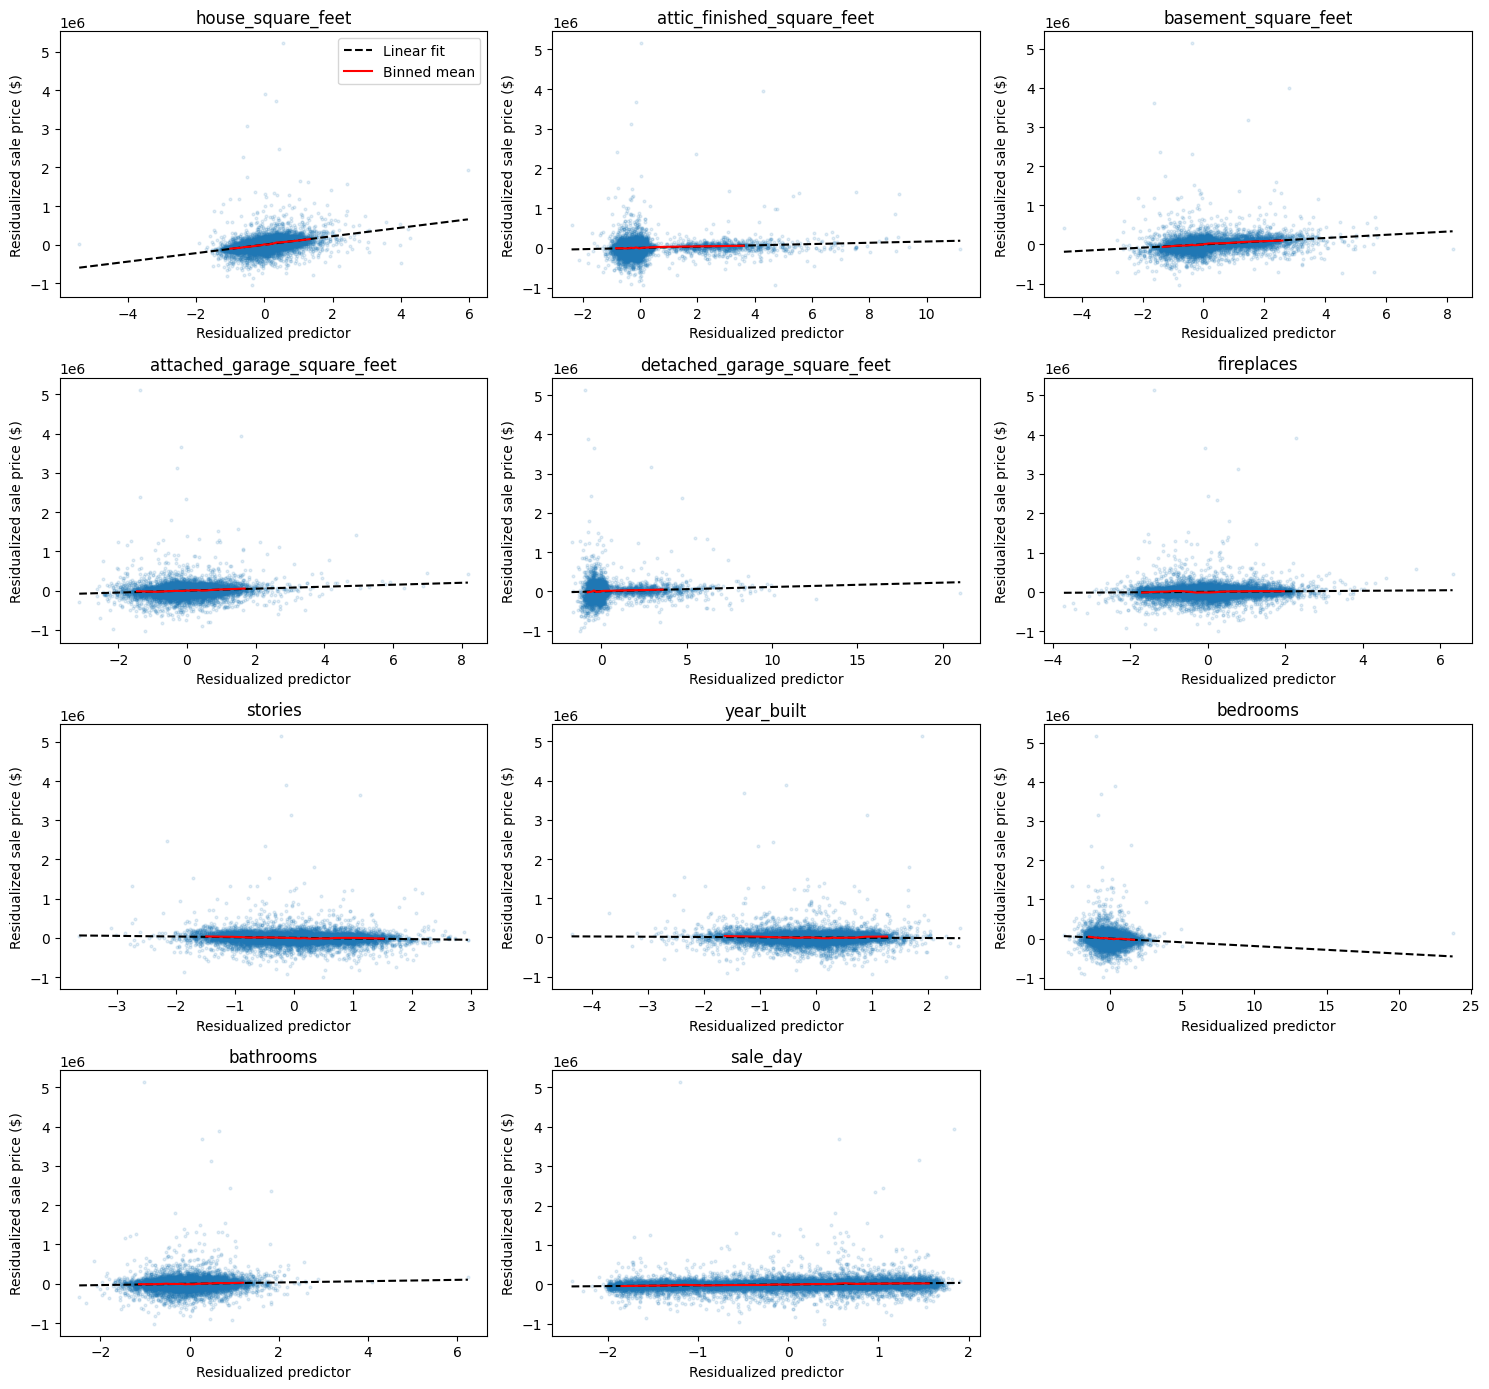

,Feature,Incremental residual R² from quadratic
7,year_built,0.006535
6,stories,0.002181
8,bedrooms,0.001581
2,basement_square_feet,0.001297
3,attached_garage_square_feet,0.001296
5,fireplaces,0.000858
4,detached_garage_square_feet,0.000583
0,house_square_feet,0.000581
9,bathrooms,0.000540
1,attic_finished_square_feet,0.000343


In [75]:


baseline = fitted_models["Numeric + categorical"]

A = baseline[0].transform(X_train)
numeric_columns = X_train.select_dtypes("number").columns.tolist()

ncols = 3
nrows = int(np.ceil(len(numeric_columns) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(15, 3.5 * nrows),
    squeeze=False,
)

curvature_results = []

for j, column in enumerate(numeric_columns):
    ax = axes.flat[j]

    controls = np.delete(A, j, axis=1)

    x_residual = (
        A[:, j]
        - LinearRegression().fit(controls, A[:, j]).predict(controls)
    )

    y_residual = np.asarray(
        y_train
        - LinearRegression().fit(controls, y_train).predict(controls)
    )

    ax.scatter(x_residual, y_residual, s=4, alpha=0.12)

    linear = LinearRegression().fit(
        x_residual.reshape(-1, 1), y_residual
    )

    grid = np.linspace(x_residual.min(), x_residual.max(), 100)
    ax.plot(
        grid,
        linear.predict(grid.reshape(-1, 1)),
        color="black",
        linestyle="--",
        label="Linear fit",
    )

    residual_data = pd.DataFrame({
        "x": x_residual,
        "y": y_residual,
    })

    bins = pd.qcut(residual_data["x"], 20, duplicates="drop")
    means = residual_data.groupby(bins, observed=True).mean()

    ax.plot(means["x"], means["y"], color="red", label="Binned mean")
    ax.set(
        title=column,
        xlabel="Residualized predictor",
        ylabel="Residualized sale price ($)",
    )

    quadratic_X = np.column_stack([
        x_residual, x_residual**2
    ])

    quadratic = LinearRegression().fit(quadratic_X, y_residual)

    curvature_results.append({
        "Feature": column,
        "Incremental residual R² from quadratic": (
            quadratic.score(quadratic_X, y_residual)
            - linear.score(x_residual.reshape(-1, 1), y_residual)
        ),
    })

for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)

axes.flat[0].legend()
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(curvature_results).sort_values(
        "Incremental residual R² from quadratic",
        ascending=False,
    )
)

The partial regression plots show each numeric predictor’s relationship with price after controlling for the other predictors. Most relationships are approximately linear where observations are concentrated. Year built shows the clearest curvature, suggesting that its relationship with price may require a nonlinear term. Several plots also contain outliers and substantial unexplained variation. These patterns motivate testing transformations and interactions. The plots alone do not establish that the nonlinearities are statistically significant.

Q6

In [76]:

def add_features(features):
    expanded = features.copy()

    # Center before squaring for better numerical behavior.
    centers = {
        "house_square_feet": 1800,
        "year_built": 1980,
        "sale_day": 182,
    }

    for column, center in centers.items():
        expanded[column + "_squared"] = (
            expanded[column] - center
        ) ** 2

    expanded["size_x_bathrooms"] = (
        expanded["house_square_feet"] * expanded["bathrooms"]
    )

    expanded["size_x_year_built"] = (
        expanded["house_square_feet"]
        * (expanded["year_built"] - 1980)
    )

    expanded["size_x_waterfront"] = (
        expanded["house_square_feet"]
        * (expanded["waterfront_type"] != "None recorded").astype(int)
    )

    expanded["size_x_view"] = (
        expanded["house_square_feet"]
        * (expanded["view_quality"] != "None recorded").astype(int)
    )

    return expanded


Z_train = add_features(X_train)
Z_test = add_features(X_test)

complex_model = make_pipeline(
    make_preprocessor(Z_train),
    LinearRegression(),
)

fold_mse = -cross_val_score(
    complex_model,
    Z_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error",
)

cv_scores["Nonlinear + interactions"] = np.sqrt(fold_mse).mean()
complex_model.fit(Z_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['house_square_feet',
                                                   'attic_finished_square_feet',
                                                   'basement_square_feet',
                                                   'attached_garage_square_feet',
                                                   'detached_garage_square_feet',
                                                   'fireplaces', 'stories',
                                                   'year_bui...
                                                   'size_x_waterfront',
                                                   'size_x_view']),
                                                 ('categorical',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['hvac_description',
                                                   'exterior', 'interior',
                                                   'roof_cover',
                                                   'waterfront_type',
                                                   'view_quality',
                                                   'utility_sewer'])])),
                ('linearregression', LinearRegression())])

I added centered squared terms for house size, year built, and sale day. I also included interactions between house size and bathrooms, year built, recorded waterfront, and recorded view. These interactions allow the relationship between size and price to depend on other housing characteristics. The complex model achieved a training RMSE of $169,065, with a test R² of 0.5484.

Compared with the best simple model, test RMSE decreased by approximately $4,463, or 2.6%. This improvement suggests that the transformations and interactions capture some additional predictive information.

Q7

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Training RMSE,Training R²,Test RMSE,Test R²
Model,,,,
Size only,190785.1238,0.2923,212579.2197,0.2860
Numeric features,169895.1189,0.4388,195278.9131,0.3975
Numeric + categorical,149432.9198,0.5658,173528.5813,0.5242
Nonlinear + interactions,146401.7164,0.5833,169065.1780,0.5484
Lasso,146496.4812,0.5827,169263.0281,0.5473


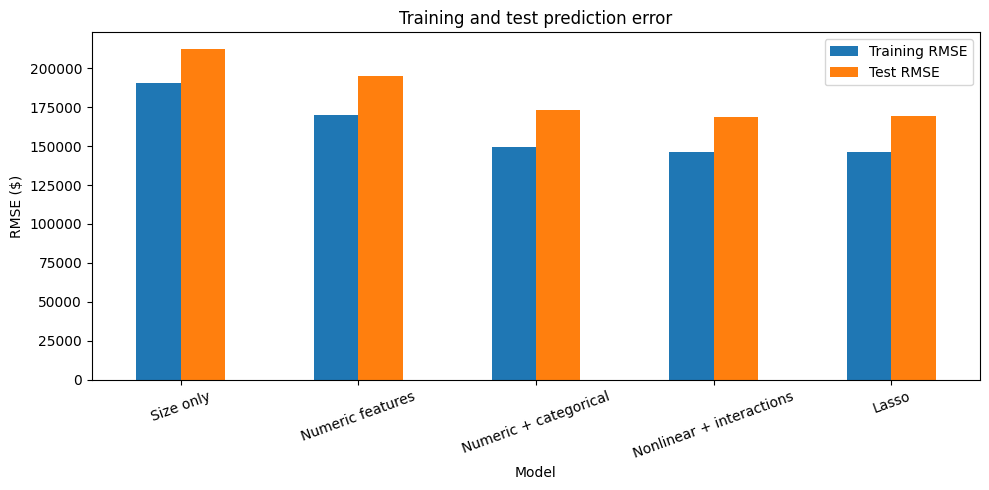

In [77]:
# 7. Compare training and test performance

models_to_evaluate = [
    (
        "Size only",
        fitted_models["Size only"],
        X_train[["house_square_feet"]],
        X_test[["house_square_feet"]],
    ),
    (
        "Numeric features",
        fitted_models["Numeric features"],
        X_train[simple_feature_sets["Numeric features"]],
        X_test[simple_feature_sets["Numeric features"]],
    ),
    (
        "Numeric + categorical",
        fitted_models["Numeric + categorical"],
        X_train,
        X_test,
    ),
    (
        "Nonlinear + interactions",
        complex_model,
        Z_train,
        Z_test,
    ),
    (
        "Lasso",
        lasso_model,
        Z_train,
        Z_test,
    ),
]

# Keep predictions in separate lists.
training_predictions = []
testing_predictions = []

for name, model, train_data, test_data in models_to_evaluate:
    training_predictions.append(model.predict(train_data))
    testing_predictions.append(model.predict(test_data))

# Calculate each metric separately.
training_rmse = []
testing_rmse = []
training_r2 = []
testing_r2 = []

for i in range(len(models_to_evaluate)):
    training_rmse.append(
        np.sqrt(mean_squared_error(y_train, training_predictions[i]))
    )
    testing_rmse.append(
        np.sqrt(mean_squared_error(y_test, testing_predictions[i]))
    )
    training_r2.append(
        r2_score(y_train, training_predictions[i])
    )
    testing_r2.append(
        r2_score(y_test, testing_predictions[i])
    )

results = pd.DataFrame({
    "Model": [item[0] for item in models_to_evaluate],
    "Training RMSE": training_rmse,
    "Training R²": training_r2,
    "Test RMSE": testing_rmse,
    "Test R²": testing_r2,
}).set_index("Model")

display(results.round(4))

results[["Training RMSE", "Test RMSE"]].plot.bar(
    figsize=(10, 5),
    rot=20,
)
plt.ylabel("RMSE ($)")
plt.title("Training and test prediction error")
plt.tight_layout()
plt.show()

The size-only model underfits because it omits many characteristics associated with house prices. Adding numeric and categorical predictors substantially improves performance.

The complex model performs better still, although its training performance exceeds its test performance. This gap indicates that the model fits the training observations more closely than unseen observations. Nevertheless, its improvement in training cross-validation and test performance suggests that the additional complexity is useful.

Training R² alone is insufficient for model selection because it generally increases when predictors are added. Cross-validation provides a better basis for selecting models, followed by a final evaluation on held-out data. These models describe predictive associations rather than causal effects.

Q8

In [78]:


lasso_pipeline = make_pipeline(
    make_preprocessor(Z_train),


    StandardScaler(),

    Lasso(
        max_iter=100000,
        tol=1e-4,
        selection="random",
        random_state=42,
    ),
)

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"lasso__alpha": np.logspace(2, 4, 9)},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=1,
)

lasso_search.fit(Z_train, y_train)
lasso_model = lasso_search.best_estimator_

print("Best alpha:", lasso_search.best_params_["lasso__alpha"])
print("Lasso CV RMSE:", np.sqrt(-lasso_search.best_score_))

feature_names = lasso_model[0].get_feature_names_out()
coefficients = lasso_model[-1].coef_

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Standardized coefficient": coefficients,
})

selected = coefficient_table.loc[
    coefficient_table["Standardized coefficient"] != 0
].copy()

selected["Absolute coefficient"] = (
    selected["Standardized coefficient"].abs()
)

selected = selected.sort_values(
    "Absolute coefficient", ascending=False
)

dropped = coefficient_table.loc[
    coefficient_table["Standardized coefficient"] == 0
]

print(f"Selected {len(selected)} of {len(coefficient_table)} features")

print("\nSelected features:")
display(selected.drop(columns="Absolute coefficient"))

print("\nFeatures set to zero:")
display(dropped)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown

Best alpha: 316.22776601683796
Lasso CV RMSE: 148629.92634289945
Selected 52 of 59 features

Selected features:


,Feature,Standardized coefficient
0,numeric__house_square_feet,69323.431556
16,numeric__size_x_waterfront,50838.969397
2,numeric__basement_square_feet,40046.198392
46,categorical__waterfront_type_WF Salt,36532.011320
14,numeric__size_x_bathrooms,31774.418098
3,numeric__attached_garage_square_feet,26191.495543
10,numeric__sale_day,20590.693359
12,numeric__year_built_squared,19641.218642
47,categorical__waterfront_type_WF Stream/Creek,-17102.288586
6,numeric__stories,-15697.742054



Features set to zero:


,Feature,Standardized coefficient
9,numeric__bathrooms,0.0
15,numeric__size_x_year_built,-0.0
18,categorical__hvac_description_Electric Baseboard,0.0
19,categorical__hvac_description_Floor Wall Furnace,0.0
30,categorical__exterior_Frame Siding,0.0
35,categorical__exterior_Masonry Concrete Block,0.0
37,categorical__exterior_Pine Finished Cabin,-0.0


I applied Lasso to the expanded feature set after standardizing all predictors. Five-fold cross-validation selected an alpha of approximately 316.23. Lasso retained 52 of 59 encoded features. Features with the largest absolute standardized coefficients included house size, size × waterfront, basement size, saltwater waterfront, size × bathrooms, and attached garage size. It set seven coefficients to zero: the standalone bathroom term, size × year built, two HVAC indicators, and three exterior indicators. Removing the standalone bathroom term does not imply that bathrooms are irrelevant, because the size × bathrooms interaction remains. Lasso achieved a training RMSE of $169,263, with a test R² of 0.5473. Lasso produced a somewhat smaller model with almost identical predictive performance. The unregularized complex model performed marginally better on this test split.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** f109bc8
- **AI tool and model used:** Chat GPT GPT-5.6 Sol

### *Prompts used

1. Review my Phase 1 solution and tell me what I should improve for Phase 2. Focus on any errors, unclear explanations, unnecessary code, or parts that could be more complete, but keep my original approach and work as much as possible.
2. Go through each section of my Phase 1 solution and tell me exactly what I should change or clarify. Provide a concise numbered list. For anything that needs improvement, explain why and suggest a specific revision.

### *AI-proposed changes


1. Q1 – Clarify data cleaning decisions. Your explanation says you excluded 83 observations with zero bedrooms, bathrooms, or stories, but your code also excludes nonpositive sale prices and house square footage. Revise the explanation to include all five conditions. Also, briefly justify excluding these observations, since zero bedrooms could potentially represent a valid property.

2. Q1 – Correct the average sale price and discuss outliers. You report an average sale price of approximately $416,500, but this is actually the median. The mean is approximately $460,712. Correct this statement and explain that the difference reflects the right-skewed distribution. Consider briefly discussing unusual observations, including the $2,000 minimum sale price, properties with 25 bedrooms, and a 2021 construction year in a dataset of 2020 sales. These should be investigated rather than automatically removed.

3. Q2 – Explain categorical encoding more clearly. Your preprocessing correctly uses median imputation for numeric variables, most-frequent imputation for remaining missing categorical values, and one-hot encoding for categorical predictors. Add a short explanation of why one-hot encoding is appropriate for regression. Clarify that "None recorded" indicates missing waterfront or view information, not necessarily the confirmed absence of those features. Your encoder also produces warnings about previously unseen categories; explain that handle_unknown="ignore" allows predictions to continue but represents those categories using the reference encoding.

4. Q3 – Keep the train-test split but clarify how it prevents data leakage. Your 80/20 split and five-fold cross-validation are implemented appropriately. Preserve this approach, but explain that preprocessing parameters are learned only from the training data within each cross-validation fold. Ideally, make feature-selection decisions using training-set EDA rather than examining the full dataset. Reserve the test set for final evaluation instead of repeatedly using it to guide model changes.

5. Q4 – Include the requested training and testing metrics directly. Your code currently displays cross-validation RMSE but does not show the training and test RMSE and R² until Q7. Either move the relevant evaluation output into Q4 or explicitly reference the later comparison table. Your conclusion is supported: the numeric-plus-categorical model performs best among the simple models, with a test RMSE of approximately $173,529 and test R² of 0.5242. You can also simplify the explanation by identifying the best model using cross-validation before discussing its test performance.

6. Q5 – Make the interpretation of nonlinearities more precise. Your partial regression plots are useful, and the residualization approach can remain unchanged. However, your quadratic comparison shows only a small improvement for year built (incremental residual R² ≈ 0.0065). Revise the discussion to say that year built shows the strongest evidence of curvature among the numeric predictors, rather than suggesting a substantial nonlinear relationship. Also clarify that your plots and incremental R² values do not establish statistical significance.

7. Q6 – Correct the training RMSE and clarify your interactions. You report a training RMSE of $169,065, but this is the test RMSE. The correct training RMSE is approximately $146,402, while the test RMSE is $169,065 and test R² is 0.5484. Your reported improvement of approximately $4,463 (2.6%) over the best simple model is correct. Keep your squared terms and interactions, but briefly explain why each was included. In particular, the waterfront and view interactions represent whether those characteristics were recorded, not necessarily their quality or actual presence.

8. Q7 – Fix the model evaluation order and simplify unnecessary code. This is the most important technical issue. Your Q7 code references lasso_model, but that model is not created until Q8. Consequently, running the notebook from top to bottom in a fresh session would produce a NameError. To preserve the assignment's order, evaluate the four non-Lasso models in Q7, then evaluate Lasso separately in Q8. You could also simplify the multiple prediction and metric lists by calculating all four metrics within one loop. Keep your discussion of overfitting and underfitting, but emphasize cross-validation performance rather than the training-test gap alone.

9. Q8 – Correct the Lasso results and strengthen the interpretation. Your Lasso explanation again confuses training and test RMSE. The correct training RMSE is approximately $146,496, the test RMSE is $169,263, and the test R² is 0.5473. Your selected alpha of approximately 316.23 and retention of 52 of 59 features are correct. Explain that Lasso removes only seven features, so the reduction in complexity is relatively modest. Also clarify that coefficients set to zero do not necessarily mean those variables have no relationship with sale price, especially when predictors are correlated or appear in interactions.

10. Overall – Improve consistency and verify the completed notebook. Use consistent rounding for RMSE and R² throughout your written explanations. Make cross-validation RMSE calculations consistent across model comparisons: your simple models average fold-level RMSEs, while the Lasso result takes the square root of average fold MSE. Before completing Phase 2, restart the kernel and run all cells in order, confirm that the outputs match your written conclusions, and ensure that the final solution is reproducible. Keep Phase 1 unchanged and document which AI suggestions you accepted, modified, or rejected.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I clarified all five filtering conditions and checked them against the Q1 cleaning code. |
| 2 | Accept | I corrected the mean sale price to approximately $460,712 using the descriptive statistics and acknowledged potential outliers. |
| 3 | Modify | My categorical preprocessing was already appropriate. I clarified one-hot encoding and how missing and unseen categories are handled. |
| 4 | Modify | I kept the original 80/20 split and five-fold cross-validation and explained how preprocessing within each fold prevents data leakage. |
| 5 | Accept | I added clearer training and testing metrics in Q4 and verified that the numeric-plus-categorical model performed best among the simple models. |
| 6 | Modify | I kept the partial regression plots and clarified that the year-built nonlinear improvement was small, with an incremental residual R² of approximately 0.0065. |
| 7 | Accept | I corrected the complex model's training RMSE to $146,402 and test RMSE to $169,065 and clarified the interaction terms. |
| 8 | Accept | I fixed the execution order by evaluating Lasso in Q8 instead of referencing it before its definition in Q7. |
| 9 | Accept | I corrected the Lasso training RMSE to $146,496 and test RMSE to $169,263 and clarified the interpretation of zero coefficients. |
| 10 | Modify | I standardized numerical reporting, reviewed cross-validation calculations, and checked that the revised explanations matched the model outputs. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [79]:
# Your Phase 2 solution to the problem goes here.


In [80]:
### Q1. Data Cleaning, EDA, and Visualization

Original shape: (16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


,Missing values
sale_date,0
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
hvac_description,7
exterior,1


Exact duplicates removed: 46
Additional records excluded: 83
Cleaned shape: (16685, 19)


,count,mean,min,25%,50%,75%,max,std
sale_date,16685,2020-07-16 17:16:05.537908224,2020-01-01 00:00:00,2020-04-27 00:00:00,2020-07-27 00:00:00,2020-10-09 00:00:00,2020-12-31 00:00:00,NaN
sale_price,16685.0,460711.533833,2000.0,348000.0,416500.0,523000.0,6130000.0,231969.664344
house_square_feet,16685.0,1882.402158,200.0,1320.0,1774.0,2352.0,9510.0,757.693748
attic_finished_square_feet,16685.0,25.010668,0.0,0.0,0.0,0.0,1212.0,102.146437
basement_square_feet,16685.0,168.610488,0.0,0.0,0.0,0.0,4000.0,430.021766
attached_garage_square_feet,16685.0,364.864249,0.0,0.0,422.0,528.0,2816.0,286.494195
detached_garage_square_feet,16685.0,38.532514,0.0,0.0,0.0,0.0,3664.0,165.237108
fireplaces,16685.0,0.891399,0.0,1.0,1.0,1.0,5.0,0.595436
stories,16685.0,1.561822,1.0,1.0,2.0,2.0,3.0,0.507524
year_built,16685.0,1980.405394,1880.0,1959.0,1990.0,2006.0,2021.0,33.310856


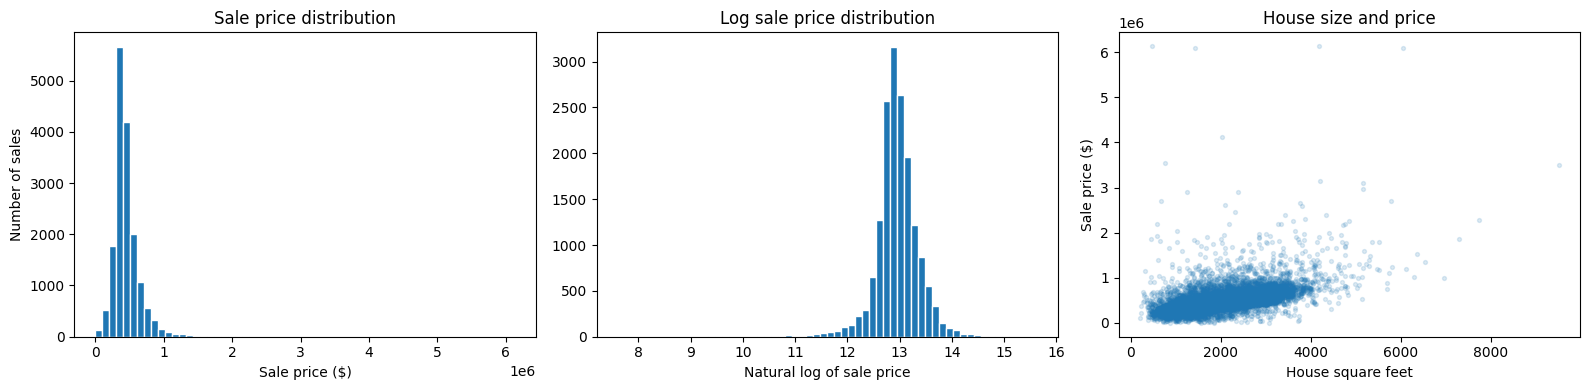

,Correlation with price
attic_finished_square_feet,0.022428
detached_garage_square_feet,0.053637
stories,0.175749
bedrooms,0.219480
year_built,0.232631
basement_square_feet,0.276343
attached_garage_square_feet,0.318509
fireplaces,0.357741
bathrooms,0.423721
house_square_feet,0.539416


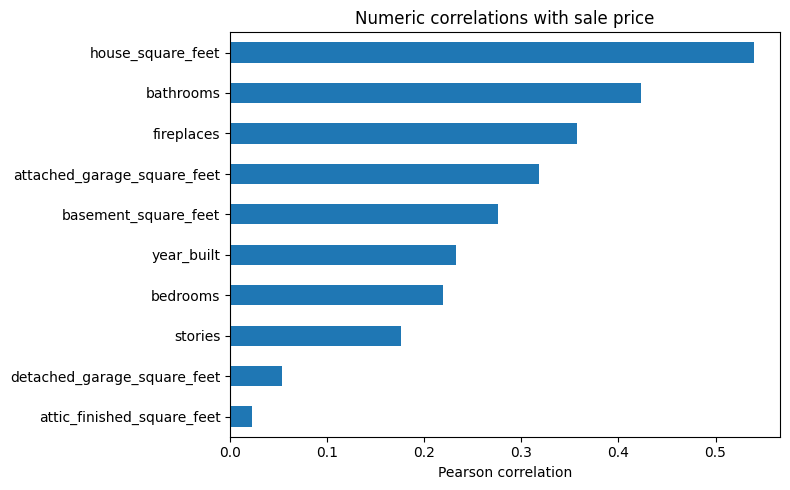

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score

raw = pd.read_csv("/data/pierce_county_house_sales.csv")

print("Original shape:", raw.shape)
display(raw.head())
display(raw.isna().sum().rename("Missing values"))

df = raw.drop_duplicates().copy()
print("Exact duplicates removed:", len(raw) - len(df))

valid = (
    (df["sale_price"] > 0)
    & (df["house_square_feet"] > 0)
    & (df["bedrooms"] > 0)
    & (df["bathrooms"] > 0)
    & (df["stories"] > 0)
)

print("Additional records excluded:", (~valid).sum())
df = df.loc[valid].copy()

df["sale_date"] = pd.to_datetime(df["sale_date"])

for column in ["waterfront_type", "view_quality"]:
    df[column] = df[column].fillna("None recorded")

print("Cleaned shape:", df.shape)
display(df.describe().T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df["sale_price"], bins=60, edgecolor="white")
axes[0].set(
    title="Sale price distribution",
    xlabel="Sale price ($)",
    ylabel="Number of sales",
)

axes[1].hist(np.log(df["sale_price"]), bins=60, edgecolor="white")
axes[1].set(
    title="Log sale price distribution",
    xlabel="Natural log of sale price",
)

axes[2].scatter(
    df["house_square_feet"], df["sale_price"],
    alpha=0.15, s=8
)
axes[2].set(
    title="House size and price",
    xlabel="House square feet",
    ylabel="Sale price ($)",
)

plt.tight_layout()
plt.show()

correlations = (
    df.select_dtypes("number")
    .corr()["sale_price"]
    .drop("sale_price")
    .sort_values()
)

display(correlations.rename("Correlation with price"))

correlations.plot.barh(figsize=(8, 5))
plt.title("Numeric correlations with sale price")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

In [82]:
# The original dataset contains 16,814 observations and 19 columns. I removed 46 exact duplicates and excluded 83 additional observations with nonpositive sale prices, house square footage, bedrooms, bathrooms, or stories. This leaves 16,685 observations. I treated these values as unusable for this analysis, although some unusual properties, such as homes with zero bedrooms, could still be valid.

# Missing waterfront and view values were labeled "None recorded," which indicates missing information rather than necessarily confirming the absence of these features. Other missing categorical values are handled through imputation during preprocessing.

# Sale prices are right-skewed, with a mean of approximately $460,712, a median of $416,500, and a maximum of $6,130,000. Some unusual values, including the $2,000 minimum sale price and properties with 25 bedrooms, warrant further investigation. I retained these observations because they are not necessarily errors. House size has the strongest individual numeric correlation with sale price, approximately 0.539.

In [83]:
### Q2 and Q3. Preprocessing and Train-Test Split

In [84]:
# 2. Prepare variables
# 3. Create the 80/20 train-test split

df["sale_day"] = (
    df["sale_date"] - pd.Timestamp("2020-01-01")
).dt.days

X = df.drop(columns=["sale_price", "sale_date"])
y = df["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


def make_preprocessor(features):
    numeric_columns = features.select_dtypes("number").columns.tolist()
    categorical_columns = features.select_dtypes("object").columns.tolist()

    numeric_pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
    )

    categorical_pipeline = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False,
        ),
    )

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])


# All learned preprocessing is fitted inside each training fold.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

Training observations: 13348
Test observations: 3337


In [85]:
# I randomly divided the cleaned data into 80% training and 20% testing using random_state=42. This produced 13,348 training observations and 3,337 test observations. I used five-fold cross-validation within the training set for model comparison and Lasso tuning.

# Numeric predictors were imputed using the median and standardized. Categorical predictors were imputed using the most frequent category and transformed through one-hot encoding. This allows categorical variables to be included in linear regression without incorrectly treating categories as numerical values.

# The encoder drops one reference category and uses handle_unknown="ignore" to accommodate categories not previously observed during training. Since preprocessing occurs within each model pipeline, its parameters are fitted separately within each training fold, preventing preprocessing-related data leakage into validation folds.

In [86]:
### Q4. Simple Linear Models and Performance

In [87]:
simple_feature_sets = {
    "Size only": ["house_square_feet"],
    "Numeric features": X_train.select_dtypes("number").columns.tolist(),
    "Numeric + categorical": X_train.columns.tolist(),
}

fitted_models = {}
cv_scores = {}
simple_rows = []

for name, columns in simple_feature_sets.items():
    model = make_pipeline(
        make_preprocessor(X_train[columns]),
        LinearRegression(),
    )

    fold_mse = -cross_val_score(
        model,
        X_train[columns],
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error",
    )

    cv_scores[name] = np.sqrt(fold_mse).mean()
    model.fit(X_train[columns], y_train)
    fitted_models[name] = model

    train_pred = model.predict(X_train[columns])
    test_pred = model.predict(X_test[columns])

    simple_rows.append({
        "Model": name,
        "Mean CV RMSE": cv_scores[name],
        "Training RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Training R²": r2_score(y_train, train_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test R²": r2_score(y_test, test_pred),
    })

simple_results = pd.DataFrame(simple_rows).set_index("Model")

display(simple_results.round(4).sort_values("Mean CV RMSE"))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Mean CV RMSE,Training RMSE,Training R²,Test RMSE,Test R²
Model,,,,,
Numeric + categorical,151000.3842,149432.9198,0.5658,173528.5813,0.5242
Numeric features,169497.5691,169895.1189,0.4388,195278.9131,0.3975
Size only,190286.2740,190785.1238,0.2923,212579.2197,0.2860


In [88]:
# The model containing both numeric and categorical predictors performs best among the simple models, with the lowest five-fold cross-validation RMSE of approximately $151,000. Its test RMSE is approximately $173,529, with a test R² of 0.5242.

# This suggests that categorical characteristics such as waterfront type, view, and building materials provide useful predictive information beyond house size and other numeric features. I used cross-validation performance to compare models rather than relying only on training performance.

In [89]:
### Q5. Partial Regression Plots and Nonlinearities

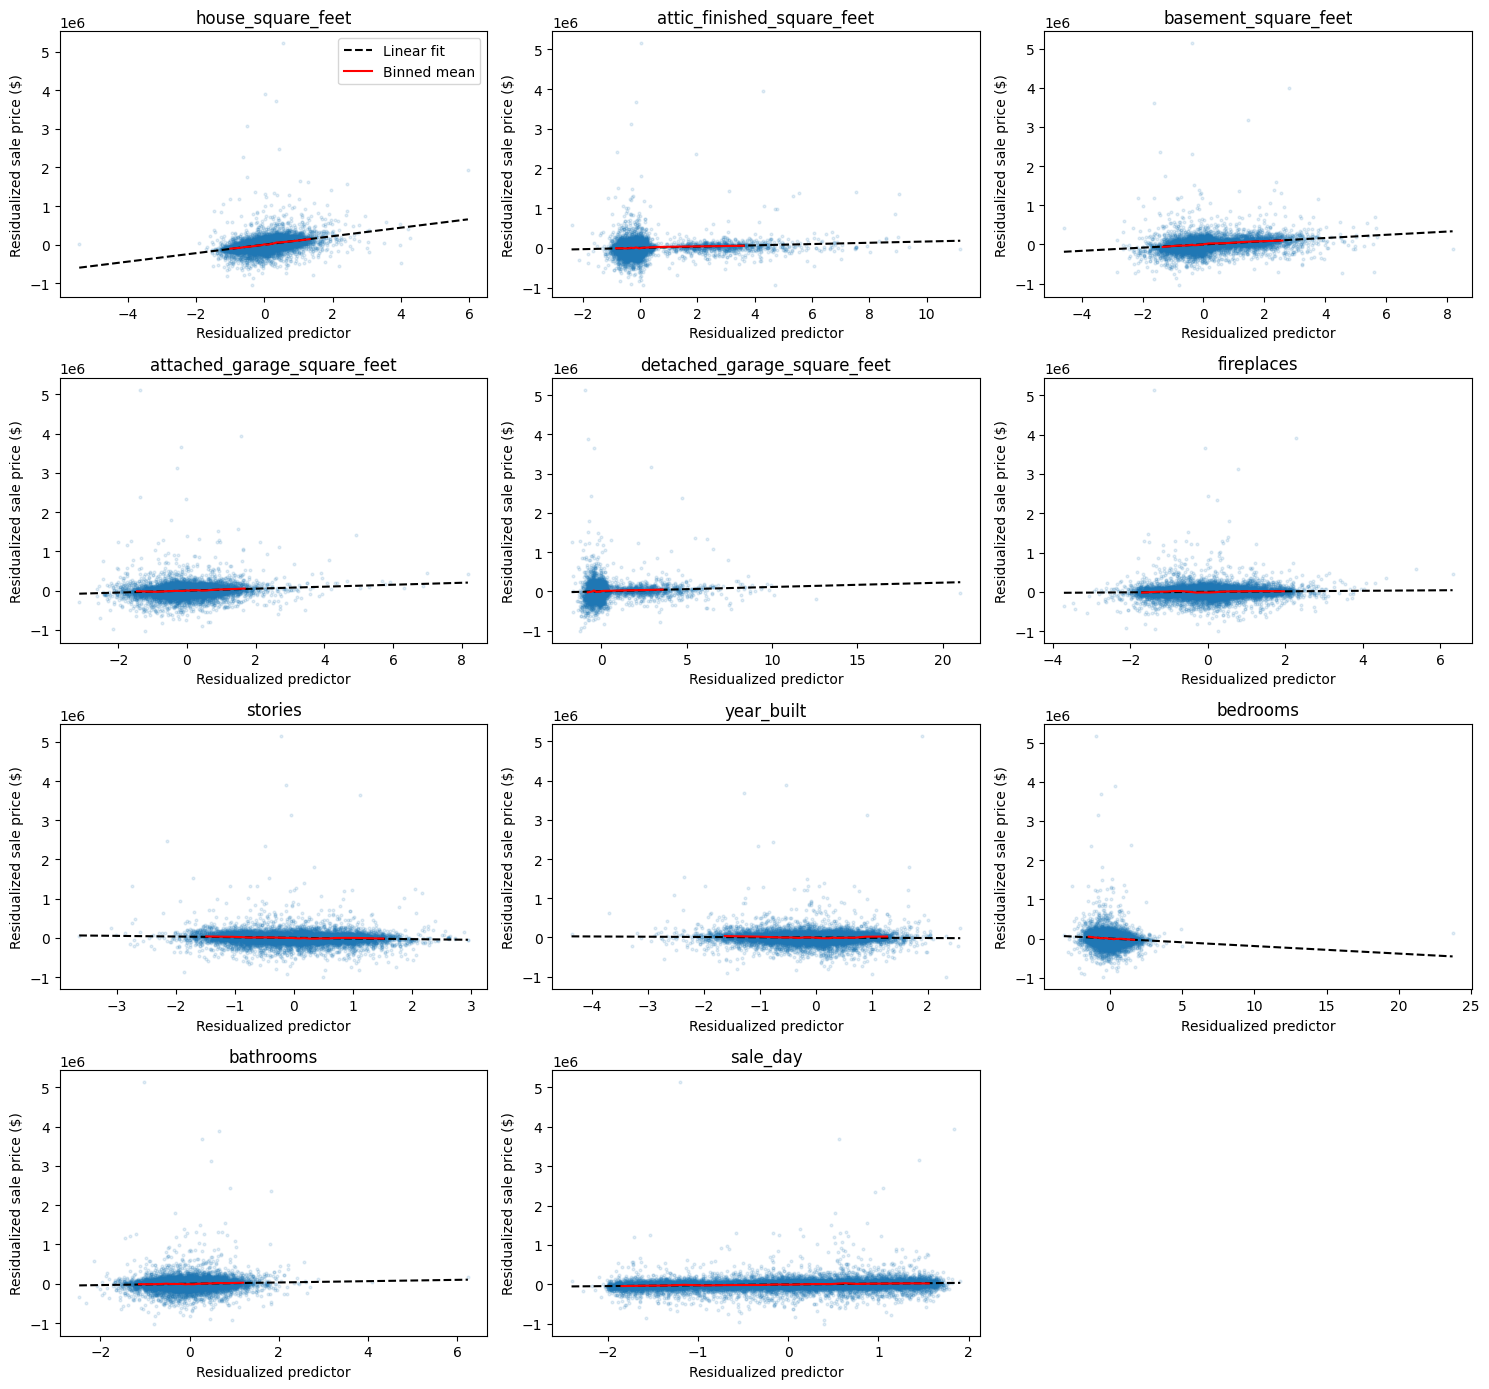

,Feature,Incremental residual R² from quadratic
7,year_built,0.006535
6,stories,0.002181
8,bedrooms,0.001581
2,basement_square_feet,0.001297
3,attached_garage_square_feet,0.001296
5,fireplaces,0.000858
4,detached_garage_square_feet,0.000583
0,house_square_feet,0.000581
9,bathrooms,0.000540
1,attic_finished_square_feet,0.000343


In [90]:
baseline = fitted_models["Numeric + categorical"]

A = baseline[0].transform(X_train)
numeric_columns = X_train.select_dtypes("number").columns.tolist()

ncols = 3
nrows = int(np.ceil(len(numeric_columns) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(15, 3.5 * nrows),
    squeeze=False,
)

curvature_results = []

for j, column in enumerate(numeric_columns):
    ax = axes.flat[j]

    controls = np.delete(A, j, axis=1)

    x_residual = (
        A[:, j]
        - LinearRegression().fit(controls, A[:, j]).predict(controls)
    )

    y_residual = np.asarray(
        y_train
        - LinearRegression().fit(controls, y_train).predict(controls)
    )

    ax.scatter(x_residual, y_residual, s=4, alpha=0.12)

    linear = LinearRegression().fit(
        x_residual.reshape(-1, 1), y_residual
    )

    grid = np.linspace(x_residual.min(), x_residual.max(), 100)

    ax.plot(
        grid,
        linear.predict(grid.reshape(-1, 1)),
        color="black",
        linestyle="--",
        label="Linear fit",
    )

    residual_data = pd.DataFrame({
        "x": x_residual,
        "y": y_residual,
    })

    bins = pd.qcut(residual_data["x"], 20, duplicates="drop")
    means = residual_data.groupby(bins, observed=True).mean()

    ax.plot(means["x"], means["y"], color="red", label="Binned mean")

    ax.set(
        title=column,
        xlabel="Residualized predictor",
        ylabel="Residualized sale price ($)",
    )

    quadratic_X = np.column_stack([
        x_residual, x_residual**2
    ])

    quadratic = LinearRegression().fit(quadratic_X, y_residual)

    curvature_results.append({
        "Feature": column,
        "Incremental residual R² from quadratic": (
            quadratic.score(quadratic_X, y_residual)
            - linear.score(x_residual.reshape(-1, 1), y_residual)
        ),
    })

for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)

axes.flat[0].legend()
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(curvature_results).sort_values(
        "Incremental residual R² from quadratic",
        ascending=False,
    )
)

In [91]:
# The partial regression plots show each numeric predictor's relationship with sale price after controlling for the other predictors. Most relationships appear approximately linear where observations are concentrated, although several plots contain outliers and substantial unexplained variation.

# Year built shows the strongest evidence of curvature among the numeric predictors, but its incremental residual R² is only approximately 0.0065. This suggests a relatively small nonlinear improvement rather than a substantial effect.

# These patterns motivate testing nonlinear transformations and interactions in the next model. However, the plots and incremental R² values alone do not establish statistical significance.

In [92]:
### Q6. Nonlinear Transformations and Interactions

In [93]:
def add_features(features):
    expanded = features.copy()

    # Center before squaring for better numerical behavior.
    centers = {
        "house_square_feet": 1800,
        "year_built": 1980,
        "sale_day": 182,
    }

    for column, center in centers.items():
        expanded[column + "_squared"] = (
            expanded[column] - center
        ) ** 2

    expanded["size_x_bathrooms"] = (
        expanded["house_square_feet"] * expanded["bathrooms"]
    )

    expanded["size_x_year_built"] = (
        expanded["house_square_feet"]
        * (expanded["year_built"] - 1980)
    )

    expanded["size_x_waterfront"] = (
        expanded["house_square_feet"]
        * (expanded["waterfront_type"] != "None recorded").astype(int)
    )

    expanded["size_x_view"] = (
        expanded["house_square_feet"]
        * (expanded["view_quality"] != "None recorded").astype(int)
    )

    return expanded


Z_train = add_features(X_train)
Z_test = add_features(X_test)

complex_model = make_pipeline(
    make_preprocessor(Z_train),
    LinearRegression(),
)

fold_mse = -cross_val_score(
    complex_model,
    Z_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error",
)

cv_scores["Nonlinear + interactions"] = np.sqrt(fold_mse).mean()
complex_model.fit(Z_train, y_train)

complex_train_pred = complex_model.predict(Z_train)
complex_test_pred = complex_model.predict(Z_test)

print("Complex model CV RMSE:", round(cv_scores["Nonlinear + interactions"], 2))
print("Training RMSE:", round(np.sqrt(mean_squared_error(y_train, complex_train_pred)), 2))
print("Training R²:", round(r2_score(y_train, complex_train_pred), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, complex_test_pred)), 2))
print("Test R²:", round(r2_score(y_test, complex_test_pred), 4))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Complex model CV RMSE: 147985.28
Training RMSE: 146401.72
Training R²: 0.5833
Test RMSE: 169065.18
Test R²: 0.5484


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [94]:
# I added centered squared terms for house size, year built, and sale day to account for possible nonlinear relationships. I also included interactions between house size and bathrooms, year built, recorded waterfront information, and recorded view information. These interactions allow the relationship between house size and sale price to vary with other property characteristics.

# The waterfront and view interactions indicate whether these characteristics were recorded rather than confirming their actual presence or quality.

# The complex model achieved a training RMSE of approximately $146,402, a test RMSE of $169,065, and a test R² of 0.5484.

# Compared with the best simple model, test RMSE decreased by approximately $4,463, or 2.6%. This suggests that the transformations and interactions capture some additional predictive information, although the improvement is relatively modest.

In [95]:
### Q7. Model Comparison and Selection

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Training RMSE,Training R²,Test RMSE,Test R²
Model,,,,
Size only,190785.1238,0.2923,212579.2197,0.2860
Numeric features,169895.1189,0.4388,195278.9131,0.3975
Numeric + categorical,149432.9198,0.5658,173528.5813,0.5242
Nonlinear + interactions,146401.7164,0.5833,169065.1780,0.5484


Five-fold CV RMSE:


,Mean CV RMSE
Nonlinear + interactions,147985.28
Numeric + categorical,151000.38
Numeric features,169497.57
Size only,190286.27


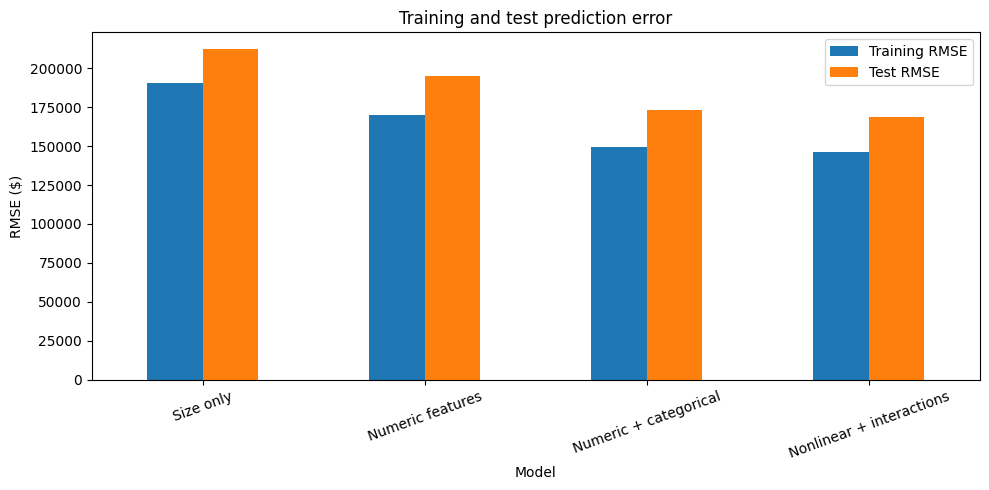

In [96]:
# Compare the four models defined so far.
# Lasso will be evaluated separately in Q8.

models_to_evaluate = [
    (
        "Size only",
        fitted_models["Size only"],
        X_train[["house_square_feet"]],
        X_test[["house_square_feet"]],
    ),
    (
        "Numeric features",
        fitted_models["Numeric features"],
        X_train[simple_feature_sets["Numeric features"]],
        X_test[simple_feature_sets["Numeric features"]],
    ),
    (
        "Numeric + categorical",
        fitted_models["Numeric + categorical"],
        X_train,
        X_test,
    ),
    (
        "Nonlinear + interactions",
        complex_model,
        Z_train,
        Z_test,
    ),
]

result_rows = []

for name, model, train_data, test_data in models_to_evaluate:
    train_pred = model.predict(train_data)
    test_pred = model.predict(test_data)

    result_rows.append({
        "Model": name,
        "Training RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Training R²": r2_score(y_train, train_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test R²": r2_score(y_test, test_pred),
    })

results = pd.DataFrame(result_rows).set_index("Model")

display(results.round(4))

print("Five-fold CV RMSE:")
display(
    pd.Series(cv_scores, name="Mean CV RMSE")
    .sort_values()
    .round(2)
    .to_frame()
)

results[["Training RMSE", "Test RMSE"]].plot.bar(
    figsize=(10, 5),
    rot=20,
)

plt.ylabel("RMSE ($)")
plt.title("Training and test prediction error")
plt.tight_layout()
plt.show()

In [97]:
# The size-only model underfits because it omits many characteristics associated with house prices. Adding numeric and categorical predictors substantially improves predictive performance.

# The complex model performs better still, although its training performance exceeds its test performance. This gap suggests that the model fits the training observations more closely than unseen observations. Nevertheless, its improvement in cross-validation and test performance indicates that the additional complexity is useful.

# Training R² alone is insufficient for model selection because it generally increases when predictors are added. Five-fold cross-validation provides a better basis for comparing models, followed by final evaluation on held-out test data.

# Overall, the nonlinear model with interactions performs best among the unregularized models. These results describe predictive associations rather than causal effects.

In [98]:
### Q8. Lasso Regularization and Feature Selection

In [99]:
lasso_pipeline = make_pipeline(
    make_preprocessor(Z_train),
    StandardScaler(),
    Lasso(
        max_iter=100000,
        tol=1e-4,
        selection="random",
        random_state=42,
    ),
)

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"lasso__alpha": np.logspace(2, 4, 9)},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=1,
)

lasso_search.fit(Z_train, y_train)
lasso_model = lasso_search.best_estimator_

# Calculate mean fold-level CV RMSE for consistency.
best_index = lasso_search.best_index_

lasso_fold_mse = [
    -lasso_search.cv_results_[f"split{i}_test_score"][best_index]
    for i in range(cv.get_n_splits())
]

lasso_cv_rmse = np.sqrt(lasso_fold_mse).mean()
cv_scores["Lasso"] = lasso_cv_rmse

print("Best alpha:", lasso_search.best_params_["lasso__alpha"])
print("Lasso CV RMSE:", round(lasso_cv_rmse, 2))

feature_names = lasso_model[0].get_feature_names_out()
coefficients = lasso_model[-1].coef_

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Standardized coefficient": coefficients,
})

selected = coefficient_table.loc[
    coefficient_table["Standardized coefficient"] != 0
].copy()

selected["Absolute coefficient"] = (
    selected["Standardized coefficient"].abs()
)

selected = selected.sort_values(
    "Absolute coefficient", ascending=False
)

dropped = coefficient_table.loc[
    coefficient_table["Standardized coefficient"] == 0
].copy()

print(f"Selected {len(selected)} of {len(coefficient_table)} features")

print("\nSelected features:")
display(selected.drop(columns="Absolute coefficient"))

print("\nFeatures set to zero:")
display(dropped)

# Evaluate Lasso after fitting it.
lasso_train_pred = lasso_model.predict(Z_train)
lasso_test_pred = lasso_model.predict(Z_test)

lasso_row = pd.DataFrame([{
    "Model": "Lasso",
    "Training RMSE": np.sqrt(mean_squared_error(y_train, lasso_train_pred)),
    "Training R²": r2_score(y_train, lasso_train_pred),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, lasso_test_pred)),
    "Test R²": r2_score(y_test, lasso_test_pred),
}]).set_index("Model")

all_results = pd.concat([results, lasso_row])

print("\nFinal model comparison:")
display(all_results.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown

Best alpha: 316.22776601683796
Lasso CV RMSE: 147882.34
Selected 52 of 59 features

Selected features:


,Feature,Standardized coefficient
0,numeric__house_square_feet,69323.431556
16,numeric__size_x_waterfront,50838.969397
2,numeric__basement_square_feet,40046.198392
46,categorical__waterfront_type_WF Salt,36532.011320
14,numeric__size_x_bathrooms,31774.418098
3,numeric__attached_garage_square_feet,26191.495543
10,numeric__sale_day,20590.693359
12,numeric__year_built_squared,19641.218642
47,categorical__waterfront_type_WF Stream/Creek,-17102.288586
6,numeric__stories,-15697.742054



Features set to zero:


,Feature,Standardized coefficient
9,numeric__bathrooms,0.0
15,numeric__size_x_year_built,-0.0
18,categorical__hvac_description_Electric Baseboard,0.0
19,categorical__hvac_description_Floor Wall Furnace,0.0
30,categorical__exterior_Frame Siding,0.0
35,categorical__exterior_Masonry Concrete Block,0.0
37,categorical__exterior_Pine Finished Cabin,-0.0



Final model comparison:


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Training RMSE,Training R²,Test RMSE,Test R²
Model,,,,
Size only,190785.1238,0.2923,212579.2197,0.2860
Numeric features,169895.1189,0.4388,195278.9131,0.3975
Numeric + categorical,149432.9198,0.5658,173528.5813,0.5242
Nonlinear + interactions,146401.7164,0.5833,169065.1780,0.5484
Lasso,146496.4812,0.5827,169263.0281,0.5473


In [100]:
#I applied Lasso to the expanded feature set after standardizing the predictors. Five-fold cross-validation selected an alpha of approximately 316.23. Lasso retained 52 of 59 encoded features.

#Features with the largest absolute standardized coefficients included house size, size × waterfront, basement size, saltwater waterfront, size × bathrooms, and attached garage size. Seven coefficients were set to zero, including the standalone bathroom term, size × year built, two HVAC indicators, and three exterior indicators.

#Removing the standalone bathroom term does not necessarily mean bathrooms are unimportant because the size × bathrooms interaction remains. More generally, coefficients set to zero do not prove that the corresponding predictors have no relationship with sale price.

#Lasso achieved a training RMSE of approximately $146,496, a test RMSE of $169,263, and a test R² of 0.5473.

#Lasso produced a somewhat smaller model with almost identical predictive performance to the unregularized complex model, which performed marginally better on this test split. Overall, regularization reduced model complexity without substantially affecting predictive accuracy.#

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements from Phase 1 to Phase 2 focused on correcting numerical errors, clarifying explanations, and improving the organization and reproducibility of the code. AI helped identify several mistakes in the original solution, including confusing the mean and median sale prices, incorrectly labeling training and testing RMSE values, and referencing the Lasso model before defining it. I also improved the explanations of preprocessing, cross-validation, nonlinear relationships, and feature selection while keeping my original modeling approach.

Although the AI suggestions were helpful, not all required substantial changes. Some recommendations involved explanations that were already mostly correct, so I chose to modify them rather than completely rewrite those sections. One limitation was that the suggested code initially used an incorrect file path, which I fixed. Additionally, the Lasso model produced repeated warnings about unknown categorical values, but these were not errors since the encoder was already configured to handle unseem categories.

I reviewed the updated model outputs and compared the reported evaluation metrics with the actual results to verify the revisions. The complex model achieved a test RMSE of approximately $169,065, compared with $169,263 for Lasso, confirming that the complex model performed slightly better. Overall, the revisions improved the clarity and consistency of the analysis. Remaining concerns include potential overfitting and the limited improvement from adding more complex freatures.